# Rainfall Prediction using ERA5-Land Weather Data (Simplified Version)

**Location:** one ERA5-Land grid point at 25.3°N, 83.0°E (around Varanasi)  |  **Period:** 1980 – 2025  |  **Data:** hourly weather from 6 CSV files

### The project in 30 seconds (say this in the interview)
> "I took 46 years of hourly weather data (temperature, humidity, pressure, wind, solar radiation and soil data), converted it into **daily data**, studied the **rainfall pattern**, and then built models that use **the previous days' weather to predict rainfall**. I did it in two ways: (1) predict **how many mm** of rain will fall, and (2) predict **whether a strong-rain day (≥ 15.6 mm) will happen or not**."

### Project flow
| Step | What we do | Why |
|---|---|---|
| 1 | Load 6 CSV files and merge them | All weather variables in one table |
| 2 | Convert units and make daily data | Rainfall is judged per day, not per hour |
| 3 | **Objective 1** – Explore the data (EDA) | Understand rainfall pattern, season, relationships |
| 4 | **Objective 2** – Predict rainfall amount (regression) | Linear Regression vs Random Forest |
| 5 | **Objective 3** – Predict strong-rain day (classification) | Logistic Regression vs Random Forest |

# Step 0: Import libraries

In [1]:
import pandas as pd                 # tables (DataFrames)
import numpy as np                  # maths
import matplotlib.pyplot as plt     # graphs
import seaborn as sns               # nicer graphs (heatmap)

# scikit-learn: models and evaluation tools
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (r2_score, mean_absolute_error, confusion_matrix,
                             classification_report, roc_auc_score,
                             average_precision_score, precision_recall_curve)

sns.set_style("whitegrid")

# Step 1: Load the 6 CSV files

ERA5-Land is a **reanalysis dataset** (a weather "history book" made by combining observations and a weather model). We downloaded the hourly values for one location. Each CSV has a different group of variables:

| File | Columns | Meaning |
|---|---|---|
| temperature | `t2m`, `d2m` | Air temperature and dew-point temperature at 2 m (Kelvin) |
| pressure-precipitation | `sp`, `tp` | Surface pressure (Pa) and total precipitation = rainfall (metres) |
| radiation | `ssrd` | Sunlight reaching the ground (J/m² per hour) |
| soil temperature | `stl1` | Temperature of the top soil layer (Kelvin) |
| soil water | `swvl1` | Moisture in the top soil layer (m³/m³) |
| wind | `u10`, `v10` | East-west and north-south wind at 10 m (m/s) |

> **Note:** keep the 6 CSV files in the **same folder** as this notebook.

In [2]:
temp         = pd.read_csv("reanalysis-era5-land-timeseries-sfc-2m-temperature_do7gif0.csv")
pressure     = pd.read_csv("reanalysis-era5-land-timeseries-sfc-pressure-precipitationbrvm8hf4.csv")
radiation    = pd.read_csv("reanalysis-era5-land-timeseries-sfc-radiation-heatxjrnv57u.csv")
soil_temp    = pd.read_csv("reanalysis-era5-land-timeseries-sfc-soil-temperature7u68706s.csv")
soil_water   = pd.read_csv("reanalysis-era5-land-timeseries-sfc-soil-waterd_lnimw7.csv")
wind         = pd.read_csv("reanalysis-era5-land-timeseries-sfc-windbdh7eoc8.csv")

temp.head()

,valid_time,d2m,t2m,latitude,longitude
0,1980-01-01 00:00:00,284.00130,285.25266,25.3,83.0
1,1980-01-01 01:00:00,283.97400,285.36853,25.3,83.0
2,1980-01-01 02:00:00,284.17050,285.69836,25.3,83.0
3,1980-01-01 03:00:00,284.51013,289.46906,25.3,83.0
4,1980-01-01 04:00:00,284.48364,292.09480,25.3,83.0


### Clean and rename the columns
* `latitude` and `longitude` are the same in every row (only one location), so we **drop** them.
* We give the short codes **readable names**.

In [3]:
# Drop latitude/longitude (same value in every row)
for table in [temp, pressure, radiation, soil_temp, soil_water, wind]:
    table.drop(columns=["latitude", "longitude"], inplace=True)

# Give readable names
temp.rename(columns={"t2m": "temp", "d2m": "dew_temp"}, inplace=True)
pressure.rename(columns={"sp": "pressure", "tp": "rain"}, inplace=True)
radiation.rename(columns={"ssrd": "solar"}, inplace=True)
soil_temp.rename(columns={"stl1": "soil_temp"}, inplace=True)
soil_water.rename(columns={"swvl1": "soil_moisture"}, inplace=True)
wind.rename(columns={"u10": "u_wind", "v10": "v_wind"}, inplace=True)

# Step 2: Merge all files into one table

All 6 files have the same hourly time column `valid_time`, so we join them on it (like matching rows by the same date-and-hour).

In [4]:
df = (temp.merge(pressure,   on="valid_time")
          .merge(radiation,  on="valid_time")
          .merge(soil_temp,  on="valid_time")
          .merge(soil_water, on="valid_time")
          .merge(wind,       on="valid_time"))

print("Shape (rows, columns):", df.shape)
print("\nMissing values in each column:")
print(df.isna().sum())
df.head()

Shape (rows, columns): (402528, 10)

Missing values in each column:
valid_time       0
dew_temp         0
temp             0
pressure         0
rain             0
solar            0
soil_temp        0
soil_moisture    0
u_wind           0
v_wind           0
dtype: int64


,valid_time,dew_temp,temp,pressure,rain,solar,soil_temp,soil_moisture,u_wind,v_wind
0,1980-01-01 00:00:00,284.00130,285.25266,100093.330,0.0,0.0,287.52594,0.171249,-1.645660,1.494232
1,1980-01-01 01:00:00,283.97400,285.36853,100148.540,0.0,0.0,287.46120,0.171280,-1.650421,1.378448
2,1980-01-01 02:00:00,284.17050,285.69836,100234.516,0.0,102073.5,287.59430,0.171310,-1.457809,1.230438
3,1980-01-01 03:00:00,284.51013,289.46906,100312.610,0.0,630119.5,289.69287,0.171280,-1.517731,1.099121
4,1980-01-01 04:00:00,284.48364,292.09480,100361.984,0.0,1021426.0,292.04562,0.171158,-1.690704,0.833801


**What we see:** about 4 lakh hourly rows (46 years × 365 days × 24 hours) and **no missing values**, so no imputation was needed.

# Step 3: Convert units and create useful variables

Raw ERA5 units are not friendly (Kelvin, Pascal, metres), so we convert them to the units we normally use.

| Variable | Conversion | Reason |
|---|---|---|
| Temperature | Kelvin − 273.15 → °C | Familiar unit |
| Pressure | Pa ÷ 100 → hPa | Familiar unit |
| Rainfall | metres × 1000 → mm | Rainfall is always reported in mm |
| Solar radiation | J/m² ÷ 1,000,000 → MJ/m² | Smaller numbers |
| Wind speed | √(u² + v²) | The file gives wind in two directions; speed combines them |
| Relative humidity (%) | From temperature and dew point (Magnus formula) | Humidity is a key factor for rain, but it is not given directly |

In [5]:
df["temp_C"]       = df["temp"] - 273.15
df["dew_temp_C"]   = df["dew_temp"] - 273.15
df["soil_temp_C"]  = df["soil_temp"] - 273.15
df["pressure_hPa"] = df["pressure"] / 100
df["rain_mm"]      = (df["rain"] * 1000).clip(lower=0)   # clip: removes tiny negative values caused by rounding
df["solar_MJ"]     = df["solar"] / 1_000_000
df["wind_speed"]   = np.sqrt(df["u_wind"]**2 + df["v_wind"]**2)

# Relative humidity from dew point (Magnus formula - a standard meteorology formula)
def saturation_vapour_pressure(t):
    return 6.1094 * np.exp(17.625 * t / (243.04 + t))

df["rh"] = 100 * saturation_vapour_pressure(df["dew_temp_C"]) / saturation_vapour_pressure(df["temp_C"])
df["rh"] = df["rh"].clip(0, 100)      # humidity must stay between 0 and 100 %

df[["temp_C", "pressure_hPa", "rain_mm", "solar_MJ", "wind_speed", "rh"]].describe().round(2)

,temp_C,pressure_hPa,rain_mm,solar_MJ,wind_speed,rh
count,402528.00,402528.00,402528.00,402528.00,402528.00,402528.00
mean,25.58,996.46,0.12,0.77,2.35,63.52
std,7.13,6.99,0.51,1.05,1.22,23.22
min,4.28,977.33,0.00,-0.00,0.01,5.98
25%,20.80,990.40,0.00,0.00,1.51,44.98
50%,26.48,996.41,0.00,0.04,2.20,67.08
75%,30.10,1002.63,0.00,1.52,2.96,83.92
max,46.67,1014.29,21.06,3.80,11.65,100.00


# Step 4: Convert hourly data to daily data

Rainfall is judged **per day** (e.g. "it rained 20 mm yesterday"), so we convert the 24 hourly rows of a day into one row:

* **Temperature:** daily max, min and mean
* **Rainfall:** daily **sum** (add up the 24 hours)
* **Solar radiation:** daily **sum**
* **Humidity, pressure, wind, soil values:** daily **mean**

In [6]:
df["valid_time"] = pd.to_datetime(df["valid_time"])
df = df.set_index("valid_time")            # make time the index so we can group by day

daily = pd.DataFrame({
    "tmax_C":        df["temp_C"].resample("D").max(),
    "tmin_C":        df["temp_C"].resample("D").min(),
    "tmean_C":       df["temp_C"].resample("D").mean(),
    "rain_mm":       df["rain_mm"].resample("D").sum(),
    "rh_mean":       df["rh"].resample("D").mean(),
    "pressure_hPa":  df["pressure_hPa"].resample("D").mean(),
    "solar_MJ":      df["solar_MJ"].resample("D").sum(),
    "soil_temp_C":   df["soil_temp_C"].resample("D").mean(),
    "soil_moisture": df["soil_moisture"].resample("D").mean(),
    "wind_speed":    df["wind_speed"].resample("D").mean(),
})

print("Daily data shape:", daily.shape)
print("Date range:", daily.index.min().date(), "to", daily.index.max().date())
daily.head()

Daily data shape: (16772, 10)
Date range: 1980-01-01 to 2025-12-01


,tmax_C,tmin_C,tmean_C,rain_mm,rh_mean,pressure_hPa,solar_MJ,soil_temp_C,soil_moisture,wind_speed
valid_time,,,,,,,,,,
1980-01-01,22.65032,12.10266,17.745669,3.214532,76.469200,1001.120380,10.381092,18.868919,0.183942,2.582601
1980-01-02,23.19283,13.38820,18.028436,0.122637,79.483295,1002.319643,12.422004,19.512615,0.202125,2.405773
1980-01-03,22.68090,12.11210,17.344493,0.062186,75.346346,1004.548602,13.553748,19.219620,0.197636,1.737879
1980-01-04,20.98855,9.87982,15.646679,0.003018,72.867408,1007.077902,12.105544,18.071003,0.193199,1.665442
1980-01-05,21.26196,9.05470,14.921583,0.001696,69.398047,1006.848378,16.036628,17.770359,0.188432,1.769270


### Quick data-quality check
We confirm there are no missing values or duplicate days, and that every variable lies in a **realistic range** (e.g. humidity 0–100 %, pressure around 1000 hPa).

In [7]:
print("Missing values:", daily.isna().sum().sum())
print("Duplicate days:", daily.index.duplicated().sum())
daily.describe().round(2).T

Missing values: 0
Duplicate days: 0


,count,mean,std,min,25%,50%,75%,max
tmax_C,16772.0,31.07,5.87,15.30,26.94,31.09,34.62,46.67
tmin_C,16772.0,20.22,6.59,4.28,14.13,22.19,25.85,34.16
tmean_C,16772.0,25.58,5.95,9.63,20.60,26.93,29.63,39.55
rain_mm,16772.0,2.77,7.32,0.00,0.00,0.00,1.59,134.50
rh_mean,16772.0,63.52,18.60,11.78,50.93,66.44,78.83,97.56
pressure_hPa,16772.0,996.46,6.88,979.82,990.40,996.32,1002.67,1012.04
solar_MJ,16772.0,18.58,5.34,1.41,15.54,18.23,22.78,29.49
soil_temp_C,16772.0,27.34,6.32,12.80,22.10,28.10,31.25,41.75
soil_moisture,16772.0,0.23,0.11,0.14,0.14,0.18,0.34,0.43
wind_speed,16772.0,2.35,0.96,0.53,1.64,2.20,2.91,7.84


**What we see:** all values are realistic (daily minimum temperature about 4 °C in winter, daily maximum up to about 47 °C in summer, humidity within 0–100 %, pressure about 980–1012 hPa, highest daily rainfall about 134 mm), so the data is clean.

---
# OBJECTIVE 1: Understand the rainfall pattern (EDA)

**Simple words:** before building any model, we first *look* at the data. When does it rain? How much? Which weather variables move together with rain?

### 1.1 Rainfall year by year

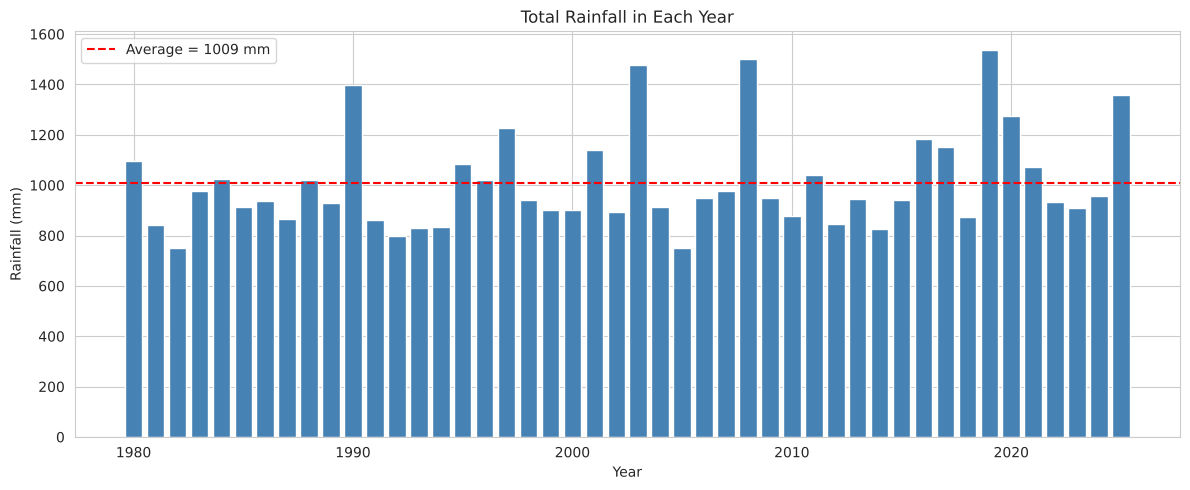

Wettest year: 2019 -> 1536 mm
Driest year : 2005 -> 749 mm


In [8]:
annual_rain = daily["rain_mm"].resample("YE").sum()      # total rainfall of each year

plt.figure(figsize=(12, 5))
plt.bar(annual_rain.index.year, annual_rain.values, color="steelblue")
plt.axhline(annual_rain.mean(), color="red", linestyle="--",
            label=f"Average = {annual_rain.mean():.0f} mm")
plt.title("Total Rainfall in Each Year")
plt.xlabel("Year")
plt.ylabel("Rainfall (mm)")
plt.legend()
plt.tight_layout()
plt.show()

print("Wettest year:", annual_rain.idxmax().year, "->", round(annual_rain.max()), "mm")
print("Driest year :", annual_rain.idxmin().year, "->", round(annual_rain.min()), "mm")

**Interpretation:** yearly rainfall changes a lot from year to year (around 750 mm to 1,500 mm) with an average of about 1,000 mm, which is a normal range for this region. There is no big upward or downward jump. *(The data for 2025 ends on 1 December, which hardly matters because December is dry.)*

### 1.2 Rainfall month by month (seasonality)

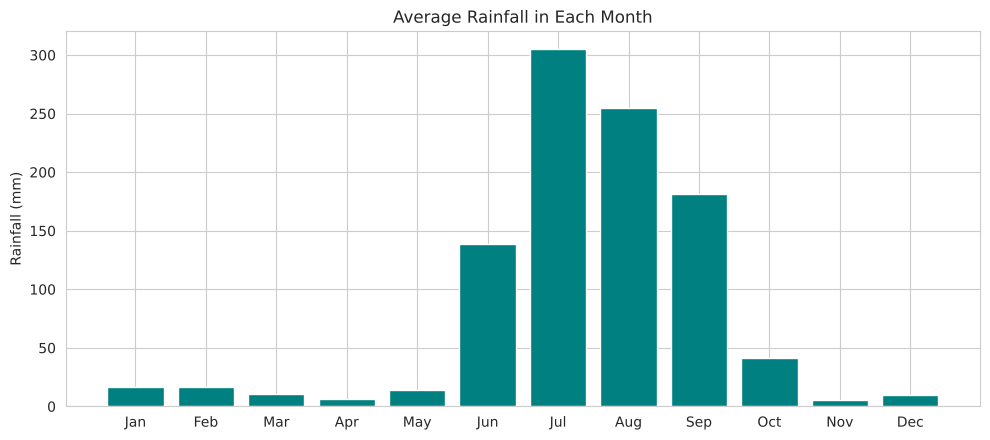

June-September (monsoon) gives 88% of the yearly rainfall


In [9]:
# Total rainfall of every month, then average it across the years (1980-2024 = complete years)
monthly_total = daily.loc[:"2024-12-31", "rain_mm"].resample("ME").sum()
avg_by_month  = monthly_total.groupby(monthly_total.index.month).mean()

month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
plt.figure(figsize=(10, 4.5))
plt.bar(month_names, avg_by_month.values, color="teal")
plt.title("Average Rainfall in Each Month")
plt.ylabel("Rainfall (mm)")
plt.tight_layout()
plt.show()

monsoon_share = avg_by_month.loc[6:9].sum() / avg_by_month.sum() * 100
print(f"June-September (monsoon) gives {monsoon_share:.0f}% of the yearly rainfall")

**Interpretation:** rainfall is strongly **seasonal**. About **88 %** of the yearly rainfall falls in the **monsoon months (June–September)**, while winter and spring are almost dry. This is why we later give the model the **month** (and other season-related clues such as humidity and soil moisture).

### 1.3 How heavy is a rainy day? (IMD categories)
The India Meteorological Department (IMD) classifies a day's rainfall into categories. We count how many days fall in each category.

In [10]:
imd_bins   = [0, 0.1, 2.5, 15.6, 64.5, 115.6, 204.5, np.inf]
imd_labels = ["No rain (<0.1)", "Very light (0.1-2.4)", "Light (2.5-15.5)", "Moderate (15.6-64.4)",
              "Heavy (64.5-115.5)", "Very heavy (115.6-204.4)", "Extremely heavy (>=204.5)"]

rain_class = pd.cut(daily["rain_mm"], bins=imd_bins, labels=imd_labels, right=False)
summary = rain_class.value_counts().reindex(imd_labels)
print(pd.DataFrame({"days": summary, "percent": (summary / len(daily) * 100).round(2)}))

                           days  percent
rain_mm                                 
No rain (<0.1)             9828    58.60
Very light (0.1-2.4)       3292    19.63
Light (2.5-15.5)           2828    16.86
Moderate (15.6-64.4)        791     4.72
Heavy (64.5-115.5)           28     0.17
Very heavy (115.6-204.4)      5     0.03
Extremely heavy (>=204.5)     0     0.00


**Interpretation:** about **59 % of days have no rain** and another **20 % have only very light rain**. Only about **5 % of days** receive 15.6 mm or more, and truly *heavy* days (64.5 mm or more) happened only **33 times in 46 years**. Such rare events are called an **imbalanced** situation, and it makes strong-rain prediction difficult. We handle it in Objective 3.

### 1.4 Which variables move together with rainfall? (Correlation)
Correlation is a number between −1 and +1. **+1** means two variables rise together, **−1** means one rises when the other falls, **0** means no linear relationship.

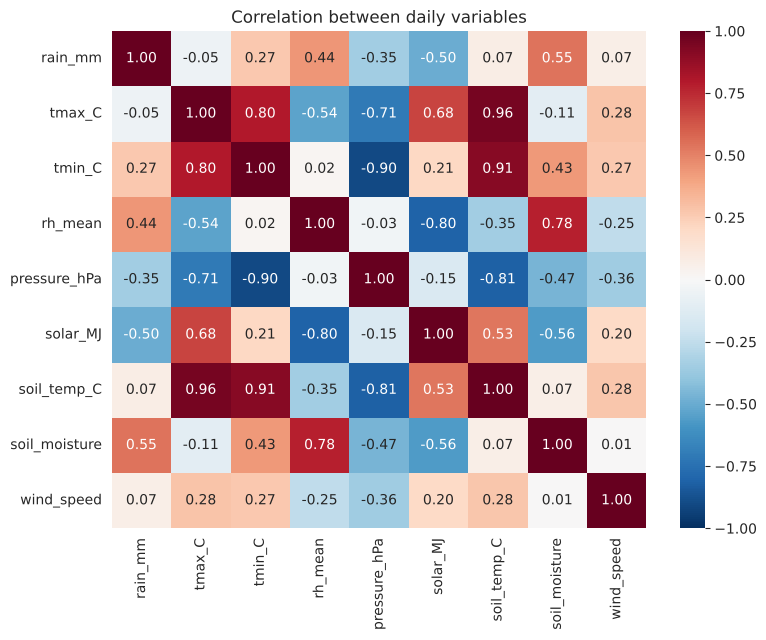

Correlation of each variable with rainfall:
solar_MJ        -0.50
pressure_hPa    -0.35
tmax_C          -0.05
wind_speed       0.07
soil_temp_C      0.07
tmin_C           0.27
rh_mean          0.44
soil_moisture    0.55
Name: rain_mm, dtype: float64


In [11]:
corr_cols = ["rain_mm", "tmax_C", "tmin_C", "rh_mean", "pressure_hPa",
             "solar_MJ", "soil_temp_C", "soil_moisture", "wind_speed"]
corr = daily[corr_cols].corr()

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlation between daily variables")
plt.tight_layout()
plt.show()

print("Correlation of each variable with rainfall:")
print(corr["rain_mm"].drop("rain_mm").sort_values().round(2))

**Interpretation:** rainfall is **positively** related to **soil moisture (0.55)** and **humidity (0.44)** (wet soil and moist air go with rain) and **negatively** related to **solar radiation (−0.50)** and **pressure (−0.35)** (sunny, high-pressure days are dry because there are no clouds). Maximum temperature, wind and soil temperature have almost no linear relationship with rain. These are same-day relationships; in the models we use the *previous* days' values as clues.

---
# OBJECTIVE 2: Predict the amount of rainfall (Regression)

**Simple words:** *"Using the weather of the previous days, how many mm of rain will fall on a given day?"*

### Idea 1: Features = "clues from the past"
Today's weather is connected with yesterday's weather. So for every day we create clues:
* **Lag features** – the value some days ago (`rain_lag1` = rain 1 day ago, `rain_lag7` = rain 7 days ago)
* **Rolling average** – the average of the last 7 days (`rain_avg7`)
* **Month** – to tell the model which season it is

> **Very important:** we only use information from **earlier days**. If we used the same day's humidity or temperature, the model would be "cheating" because it would already know the weather it is trying to predict.

In [12]:
data = daily.copy()

# --- Rainfall clues from the past ---
data["rain_lag1"] = data["rain_mm"].shift(1)    # rain 1 day ago
data["rain_lag2"] = data["rain_mm"].shift(2)    # rain 2 days ago
data["rain_lag3"] = data["rain_mm"].shift(3)    # rain 3 days ago
data["rain_lag7"] = data["rain_mm"].shift(7)    # rain 7 days ago
data["rain_avg7"] = data["rain_mm"].shift(1).rolling(7).mean()   # average rain of the previous 7 days

# --- Other weather clues from yesterday ---
data["tmax_lag1"]          = data["tmax_C"].shift(1)
data["rh_lag1"]            = data["rh_mean"].shift(1)
data["pressure_lag1"]      = data["pressure_hPa"].shift(1)
data["wind_lag1"]          = data["wind_speed"].shift(1)
data["solar_lag1"]         = data["solar_MJ"].shift(1)
data["soil_moisture_lag1"] = data["soil_moisture"].shift(1)

# --- Season clue ---
data["month"] = data.index.month

# The first few days have no "past", so they contain missing values -> remove them
data = data.dropna()
print("Rows available for modelling:", len(data))

Rows available for modelling: 16765


### Idea 2: Transform the target with `log(1 + rain)`
Most days have 0 mm of rain and a few days have a lot (for example 80 mm). Such **skewed** data is hard for a model, because a few huge values dominate. Taking `log(1 + rain)` squeezes the big values, so the model learns the pattern better. We convert predictions back to mm at the end with `expm1`.

In [13]:
data["rain_log"] = np.log1p(data["rain_mm"])      # log(1 + rain)

feature_columns = ["rain_lag1", "rain_lag2", "rain_lag3", "rain_lag7", "rain_avg7",
                   "tmax_lag1", "rh_lag1", "pressure_lag1", "wind_lag1",
                   "solar_lag1", "soil_moisture_lag1", "month"]
print("Number of features:", len(feature_columns))

Number of features: 12


### Idea 3: Split the data by **time** (not randomly)
* **Training set:** 1980 – 2018 → the model learns from this
* **Test set:** 2019 – 2025 → the model is checked on these "future" years it has never seen

For time-series data we never shuffle randomly. In real life we predict the future from the past, so the test set must come *after* the training set.

In [14]:
train = data.loc[:"2018-12-31"]
test  = data.loc["2019-01-01":]

X_train, X_test = train[feature_columns], test[feature_columns]
y_train, y_test = train["rain_log"],      test["rain_log"]

print("Training days:", len(train), "(", train.index.min().date(), "to", train.index.max().date(), ")")
print("Testing days :", len(test),  "(", test.index.min().date(),  "to", test.index.max().date(),  ")")

Training days: 14238 ( 1980-01-08 to 2018-12-31 )
Testing days : 2527 ( 2019-01-01 to 2025-12-01 )


### Models used
1. **Baseline (always predict the training average)** – a "dumb" reference. A real model must beat it.
2. **Linear Regression** – draws the best straight-line relationship between features and rainfall. Simple and easy to explain.
3. **Random Forest** – builds **many decision trees** and averages their answers. *Analogy:* instead of asking one person, we ask 200 people and take the average. It can capture non-linear patterns (for example, rain only after humidity crosses a level).

In [15]:
# Baseline: predict the same average value for every day
baseline_pred = np.full(len(y_test), y_train.mean())

# Model 1: Linear Regression
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
lin_pred = lin_reg.predict(X_test).clip(min=0)          # rain cannot be negative

# Model 2: Random Forest
rf_reg = RandomForestRegressor(n_estimators=200, max_depth=10, min_samples_leaf=5,
                               random_state=42, n_jobs=-1)
rf_reg.fit(X_train, y_train)
rf_pred = rf_reg.predict(X_test)

### Evaluation metrics
* **R²** – how much of the ups and downs of rainfall the model explains. 1 = perfect, 0 = no better than the average.
* **MAE (log scale)** – average size of the error on the log scale. Lower is better.
* **MAE (mm)** – average error in real mm per day. Lower is better.

In [16]:
def regression_scores(name, y_true_log, y_pred_log):
    r2      = r2_score(y_true_log, y_pred_log)
    mae_log = mean_absolute_error(y_true_log, y_pred_log)
    mae_mm  = mean_absolute_error(np.expm1(y_true_log), np.expm1(y_pred_log))   # back to mm
    return {"Model": name, "R2": round(r2, 3), "MAE (log)": round(mae_log, 3), "MAE (mm)": round(mae_mm, 2)}

reg_results = pd.DataFrame([
    regression_scores("Baseline (average)", y_test, baseline_pred),
    regression_scores("Linear Regression",  y_test, lin_pred),
    regression_scores("Random Forest",      y_test, rf_pred),
])
reg_results

,Model,R2,MAE (log),MAE (mm)
0,Baseline (average),-0.004,0.802,3.38
1,Linear Regression,0.586,0.430,2.76
2,Random Forest,0.656,0.362,2.33


**Interpretation**
* The **baseline** has R² ≈ 0, so it explains nothing. Both models do much better.
* **Random Forest is the best model:** R² ≈ 0.66 (Linear Regression ≈ 0.59) and the lowest error (about 2.3 mm per day against 3.4 mm for the baseline).
* Random Forest beats Linear Regression because the relation between weather and rain is **not a straight line** (for example, rain depends on the season and the humidity level together).
* **Be honest:** an average error of about 2.3 mm per day is still large when the average rainfall is only about 2.8 mm per day. Much of the model's skill comes from separating the **wet monsoon season** from the **dry season** and from the fact that rainy days come in spells. Predicting the exact amount on a particular day is hard.

### Actual vs predicted rainfall (monsoon season of one test year, in mm)

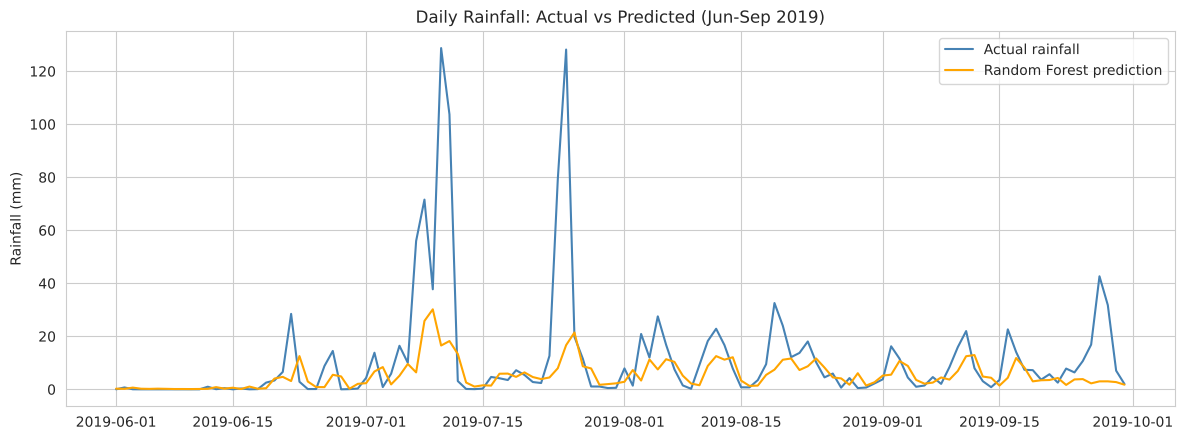

In [17]:
period = test.loc["2019-06-01":"2019-09-30"]
pred_mm = pd.Series(np.expm1(rf_reg.predict(period[feature_columns])), index=period.index)

plt.figure(figsize=(12, 4.5))
plt.plot(period.index, period["rain_mm"], label="Actual rainfall", color="steelblue")
plt.plot(period.index, pred_mm,           label="Random Forest prediction", color="orange")
plt.title("Daily Rainfall: Actual vs Predicted (Jun-Sep 2019)")
plt.ylabel("Rainfall (mm)")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation:** the predictions follow the **rise and fall** of rainfall (wet spells and dry spells), but the model does not reach the very highest peaks. This is normal: models trained to minimise average error tend to predict "safe, middle" values, and extreme rain is hard to predict from past weather alone.

---
# OBJECTIVE 3: Predict a strong-rain day (Classification)

**Simple words:** *"Will tomorrow be a strong-rain day: **Yes or No**?"*

We call a day a **strong-rain day** if it receives **15.6 mm or more**, which is the IMD threshold where rain changes from "light" to "moderate or heavy". This type of prediction is useful for warnings (waterlogging, farming decisions).

We use the **same features and same time-split** as in Objective 2.

In [18]:
# 1 = strong-rain day (15.6 mm or more), 0 = otherwise
data["strong_rain"] = (data["rain_mm"] >= 15.6).astype(int)

train = data.loc[:"2018-12-31"]
test  = data.loc["2019-01-01":]

X_train, X_test = train[feature_columns], test[feature_columns]
y_train, y_test = train["strong_rain"],   test["strong_rain"]

print("Strong-rain days in training data: ", y_train.sum(), "out of", len(y_train),
      f"({y_train.mean()*100:.1f}%)")
print("Strong-rain days in test data     : ", y_test.sum(),  "out of", len(y_test),
      f"({y_test.mean()*100:.1f}%)")

Strong-rain days in training data:  672 out of 14238 (4.7%)
Strong-rain days in test data     :  152 out of 2527 (6.0%)


### The imbalance problem
Only about **5 out of 100 days** are strong-rain days. If a model simply said **"No strong rain"** every day, it would be ~95 % accurate but completely useless. So:

1. **Accuracy is not a good metric here.** We use **Precision, Recall, F1 and PR-AUC** instead.
2. We use `class_weight="balanced"`, which tells the model: *"a mistake on a rare strong-rain day is more costly than a mistake on a normal day."*

### Models used
1. **Logistic Regression** – gives the **probability** of strong rain (0 to 1). If probability > 0.5 → "Yes". Simple and easy to explain. It needs scaled features, so we scale them first.
2. **Random Forest Classifier** – many decision trees voting "Yes" or "No".

In [19]:
# Scaling (only for Logistic Regression): put all features on a similar scale.
# fit on TRAIN only, then apply the same scaling to test
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# Model 1: Logistic Regression
log_model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_train)
log_pred = log_model.predict(X_test_scaled)                 # Yes/No answer
log_prob = log_model.predict_proba(X_test_scaled)[:, 1]     # probability of "Yes"

# Model 2: Random Forest Classifier
rf_clf = RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=5,
                                class_weight="balanced", random_state=42, n_jobs=-1)
rf_clf.fit(X_train, y_train)
rf_cls_pred = rf_clf.predict(X_test)
rf_cls_prob = rf_clf.predict_proba(X_test)[:, 1]

### Confusion matrix (the basic result table)
| | Predicted **No** | Predicted **Yes** |
|---|---|---|
| **Actually No** | True Negative (correct) | False Positive (false alarm) |
| **Actually Yes** | False Negative (missed event) | True Positive (correct) |

* **Precision** = of the days we warned "strong rain", how many really had it? (avoids false alarms)
* **Recall** = of all real strong-rain days, how many did we catch? (avoids missed events)
* **F1** = a balance of precision and recall

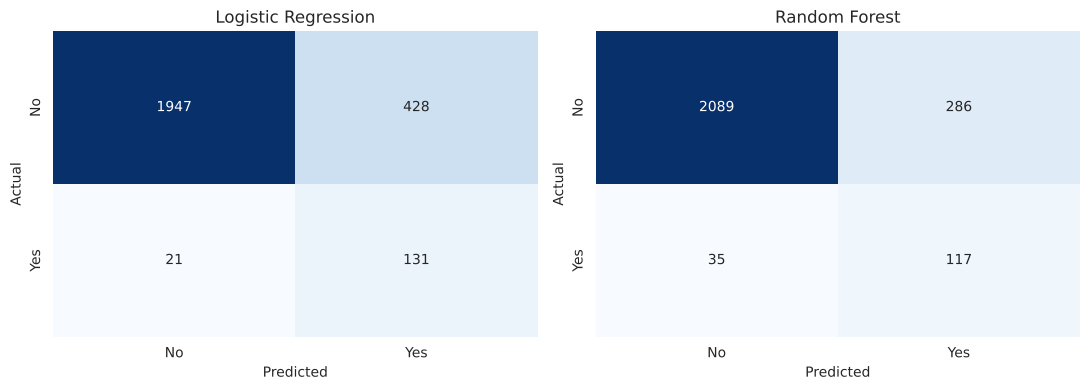

===== Logistic Regression =====
                precision    recall  f1-score   support

No strong rain       0.99      0.82      0.90      2375
   Strong rain       0.23      0.86      0.37       152

      accuracy                           0.82      2527
     macro avg       0.61      0.84      0.63      2527
  weighted avg       0.94      0.82      0.86      2527

===== Random Forest =====
                precision    recall  f1-score   support

No strong rain       0.98      0.88      0.93      2375
   Strong rain       0.29      0.77      0.42       152

      accuracy                           0.87      2527
     macro avg       0.64      0.82      0.68      2527
  weighted avg       0.94      0.87      0.90      2527



In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name, pred in zip(axes, ["Logistic Regression", "Random Forest"], [log_pred, rf_cls_pred]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

print("===== Logistic Regression =====")
print(classification_report(y_test, log_pred, target_names=["No strong rain", "Strong rain"]))
print("===== Random Forest =====")
print(classification_report(y_test, rf_cls_pred, target_names=["No strong rain", "Strong rain"]))

### Summary table of metrics
* **ROC-AUC** – how well the model **ranks** strong-rain days above normal days (0.5 = random guessing, 1 = perfect).
* **PR-AUC** – same idea, but focused on the rare "Yes" class, so it is the **most honest metric for imbalanced data**. Compare it with the *baseline*: a random model would score only about the strong-rain percentage (~5 %).

In [21]:
from sklearn.metrics import precision_score, recall_score, f1_score

def classification_scores(name, y_true, y_pred, y_prob):
    return {"Model": name,
            "Precision": round(precision_score(y_true, y_pred), 3),
            "Recall":    round(recall_score(y_true, y_pred), 3),
            "F1":        round(f1_score(y_true, y_pred), 3),
            "ROC-AUC":   round(roc_auc_score(y_true, y_prob), 3),
            "PR-AUC":    round(average_precision_score(y_true, y_prob), 3)}

cls_results = pd.DataFrame([
    classification_scores("Logistic Regression", y_test, log_pred, log_prob),
    classification_scores("Random Forest",       y_test, rf_cls_pred, rf_cls_prob),
])
print("Baseline PR-AUC (random guessing) =", round(y_test.mean(), 3))
cls_results

Baseline PR-AUC (random guessing) = 0.06


,Model,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.234,0.862,0.368,0.912,0.369
1,Random Forest,0.290,0.770,0.422,0.917,0.365


**Interpretation**
* **Accuracy looks lower than a useless "always No" model** (which would score about 94 %), yet our models are far more useful, because they actually find the strong-rain days. This is the reason we do not use accuracy here.
* **Logistic Regression** catches more events (**recall ≈ 0.86**) but gives more false alarms (precision ≈ 0.23).
* **Random Forest** has fewer false alarms (**precision ≈ 0.29**) and a better F1 (≈ 0.42 against 0.37), but catches a few less events (recall ≈ 0.77).
* **PR-AUC is about 0.37 for both models, roughly 6 times the random baseline of 0.06**, and ROC-AUC is about 0.91–0.92. So the models have real skill, and the simple Logistic Regression is almost as good as the Random Forest.
* In practice, for a **warning system**, missing a strong-rain day is usually worse than a false alarm, so a model with high recall is preferred.

### Precision-Recall curve

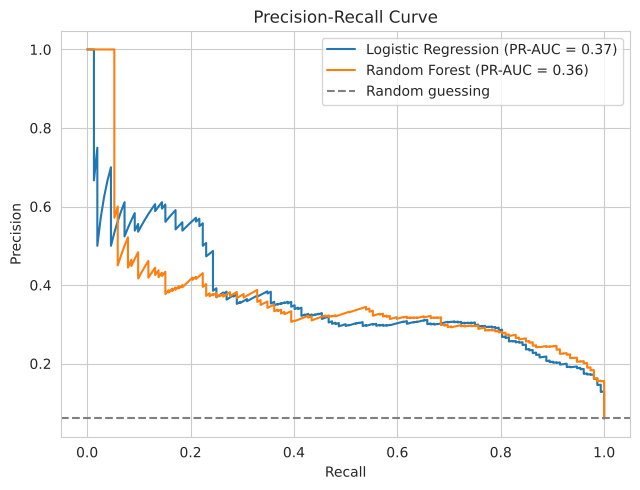

In [22]:
plt.figure(figsize=(6.5, 5))
for name, prob in [("Logistic Regression", log_prob), ("Random Forest", rf_cls_prob)]:
    p, r, _ = precision_recall_curve(y_test, prob)
    plt.plot(r, p, label=f"{name} (PR-AUC = {average_precision_score(y_test, prob):.2f})")
plt.axhline(y_test.mean(), color="grey", linestyle="--", label="Random guessing")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.tight_layout()
plt.show()

**How to read it:** if we want to catch more strong-rain days (higher **recall**), we must accept more false alarms (lower **precision**). The higher the curve is above the grey line, the better the model.

### Which features matter most? (Random Forest feature importance)

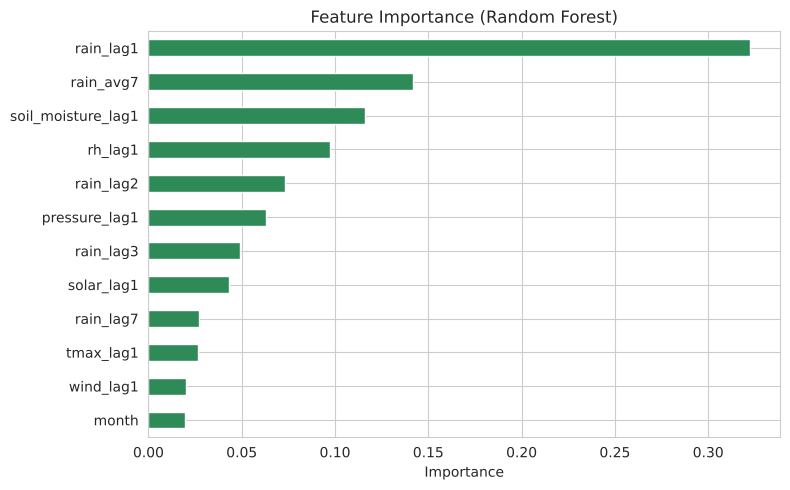

rain_lag1             0.322
rain_avg7             0.142
soil_moisture_lag1    0.116
rh_lag1               0.097
rain_lag2             0.073
pressure_lag1         0.063
rain_lag3             0.049
solar_lag1            0.043
rain_lag7             0.027
tmax_lag1             0.026
wind_lag1             0.020
month                 0.020
dtype: float64

In [23]:
importance = pd.Series(rf_clf.feature_importances_, index=feature_columns).sort_values()

plt.figure(figsize=(8, 5))
importance.plot(kind="barh", color="seagreen")
plt.title("Feature Importance (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

importance.sort_values(ascending=False).round(3)

**Interpretation:** the most useful clue is **how much it rained yesterday** (`rain_lag1`), followed by the **average rain of the last 7 days** (`rain_avg7`), **soil moisture** and **humidity** of the previous day. This makes sense physically: rain comes in wet spells, and wet soil and humid air mean the atmosphere is already in a "rainy mood". Temperature and wind are the least useful.

---
# Conclusion

* **Objective 1 (EDA):** Rainfall here is highly seasonal: about **88 % falls in June–September**. About 59 % of days are completely dry, and only about 5 % of days get 15.6 mm or more. Rain is linked with high soil moisture and humidity, and with low solar radiation and low pressure.
* **Objective 2 (amount of rain):** Random Forest was best (**R² ≈ 0.66** on the log scale, average error about **2.3 mm/day**), better than Linear Regression (R² ≈ 0.59) and the baseline.
* **Objective 3 (strong-rain day):** Logistic Regression and Random Forest both have real skill (**PR-AUC ≈ 0.37 against 0.06 for random guessing**, ROC-AUC ≈ 0.91). Logistic Regression has the higher recall (0.86), Random Forest the better precision and F1.
* **Main learning:** the previous day's rainfall, the last 7 days' rainfall, soil moisture and humidity are the strongest clues for tomorrow's rain.

### Limitations (be honest in the interview)
* Data comes from **one grid point** and from a **reanalysis model**, not from a physical rain-gauge station.
* We use only **past weather at the same place**. Real forecasting also uses satellite, radar and large-scale weather models, which we do not have.
* Strong-rain days are rare, so predicting them is hard; many warnings will be false alarms.

### Future work
* Add more locations or more variables (for example wind direction, cloud cover).
* Tune the models and try other models such as XGBoost.
* Try time-series models such as ARIMA for comparison.

---
# Likely interview questions and simple answers

**1. What is the objective of your project?**
To study the rainfall pattern of the region and to predict rainfall (amount, and strong-rain yes/no) using the previous days' weather.

**2. What is the data?**
ERA5-Land reanalysis, hourly, 1980–2025, for one location. Six files: temperature, pressure and precipitation, solar radiation, soil temperature, soil water and wind. About 4 lakh rows with no missing values.

**3. What preprocessing did you do?**
Dropped latitude/longitude, merged the 6 files on time, converted units (K→°C, Pa→hPa, m→mm), calculated wind speed and relative humidity, converted hourly data to daily (sum for rain, max/min/mean for temperature, mean for the others), and checked for missing values and unrealistic values.

**4. Why did you convert hourly data into daily data?**
Rainfall is reported and used per day. Daily data is also less noisy than hourly data.

**5. What are lag features and why did you use them?**
A lag feature is the value of a variable some days earlier (for example, rain yesterday). Weather is connected over time, so yesterday's weather helps to predict today's.

**6. How did you avoid data leakage?**
All features come from earlier days (`shift(1)` or more), and the rolling average also uses `shift(1)`, so the model never sees the day it predicts. The train-test split is by time, not random.

**7. Why did you use `log(1 + rain)`?**
Rainfall is highly skewed (many zeros and a few huge values). The log transform reduces the effect of the huge values. I convert back to mm using `expm1`.

**8. Why not a random train-test split?**
In real life we predict the future from the past. A random split would mix future days into the training data and give unrealistically good results.

**9. Why Random Forest?**
It averages many decision trees, handles non-linear relationships, needs no heavy preprocessing and is hard to overfit. I compared it with Linear/Logistic Regression as simple baselines.

**10. Your classes are imbalanced. What did you do?**
Only about 5 % of days are strong-rain days. I used `class_weight="balanced"` and judged the models with Precision, Recall, F1 and PR-AUC instead of accuracy.

**11. What is the difference between precision and recall?**
Precision: of the warnings given, how many were correct. Recall: of the real events, how many were caught.

**12. Why did you take 15.6 mm as the threshold?**
It is the IMD limit where rainfall changes from "light" to "moderate". It gives enough strong-rain days to learn from, whereas truly "heavy" days (64.5 mm or more) are too few for a model.

**13. What would you improve?**
More locations, more variables, hyper-parameter tuning, and comparison with time-series models such as ARIMA.